# Pod Service Reuse Analysis
## Baseline vs Transformation Service Reuse (S4)

All metrics are computed directly from the experiment directories (Kepler energy CSVs and `run.json`). Nothing is hardcoded, so the figures always reflect the latest experiment outputs.

In [3]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'figure.dpi': 150,
    'axes.grid': True,
    'grid.alpha': 0.3
})

BASE_DIR = Path('~/Desktop/paper_experiments').expanduser()

# (folder, user_count) per scenario
EXPERIMENTS = {
    'Baseline U2':    (BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_06_56_27_df3720c9', 2),
    'Baseline U4':    (BASE_DIR / 'baseline_sequential' / 'nextflow_rnaseq_partial_resume_2026_05_28_08_23_15_380543a9', 4),
    'Pod Service U2': (BASE_DIR / 'pod_service' / 'nextflow_rnaseq_partial_resume_2026_05_29_08_49_05_177a4c52', 2),
    'Pod Service U4': (BASE_DIR / 'pod_service' / 'nextflow_rnaseq_partial_resume_2026_05_29_09_47_52_7125d12a', 4),
}

tasks_per_user = 548
KEPLER_SAMPLE_INTERVAL_S = 10   # sampling interval of the kepler power series, in seconds

def load_csv(folder, name):
    path = Path(folder) / 'data' / name
    if not path.exists():
        raise FileNotFoundError(f'Missing CSV: {path}')
    return pd.read_csv(path)

def load_run_json(folder):
    p = Path(folder) / 'run.json'
    if not p.exists():
        raise FileNotFoundError(f'Missing run.json: {p}')
    return json.loads(p.read_text())

def get_treatment(df):
    if 'treatment' in df.columns:
        return df[df['treatment'] == 'Treatment'].copy()
    return df.copy()

def get_energy_kj(folder):
    """Sum kepler CPU power samples (W) over the treatment window and
    integrate over the sample interval to get energy, returned in kJ."""
    df = load_csv(folder, 'kepler_node_cpu_power_sum.csv')
    energy_j = get_treatment(df)['kepler_node_cpu_power_sum'].sum() * KEPLER_SAMPLE_INTERVAL_S
    return energy_j / 1000.0

def get_duration_min(folder):
    """treatment_duration is stored in seconds in run.json -> convert to minutes."""
    rj = load_run_json(folder)
    return rj['treatment_duration'] / 60.0

# Compute every metric from the experiment directories
data = {}
for label, (folder, users) in EXPERIMENTS.items():
    energy_kj = get_energy_kj(folder)
    duration_min = get_duration_min(folder)
    total_tasks = users * tasks_per_user
    throughput = total_tasks / duration_min
    data[label] = {
        'energy_kj': energy_kj,
        'duration_min': duration_min,
        'throughput': throughput,
        'users': users,
    }

scenarios  = ['Baseline', 'Pod Service']
keys_u2 = ['Baseline U2', 'Pod Service U2']
keys_u4 = ['Baseline U4', 'Pod Service U4']
x = np.arange(len(scenarios))
width = 0.35
colors_u2 = ['#1f77b4', '#1f77b4']
colors_u4 = ['#d62728', '#d62728']

def pct_change(baseline_key, reuse_key, metric):
    """Signed percent change of reuse vs baseline for a given metric."""
    b = data[baseline_key][metric]
    r = data[reuse_key][metric]
    return (r - b) / b * 100.0

# Sanity-check the computed values against the directories
for k, v in data.items():
    print(f"{k:16s} energy={v['energy_kj']:7.2f} kJ  "
          f"duration={v['duration_min']:7.2f} min  throughput={v['throughput']:6.2f} tasks/min")
print('Setup done')

Baseline U2      energy= 214.99 kJ  duration=  85.78 min  throughput= 12.78 tasks/min
Baseline U4      energy= 432.18 kJ  duration= 172.89 min  throughput= 12.68 tasks/min
Pod Service U2   energy= 182.41 kJ  duration=  57.78 min  throughput= 18.97 tasks/min
Pod Service U4   energy= 365.87 kJ  duration= 115.60 min  throughput= 18.96 tasks/min
Setup done


## Plot 1 — Total Energy Comparison

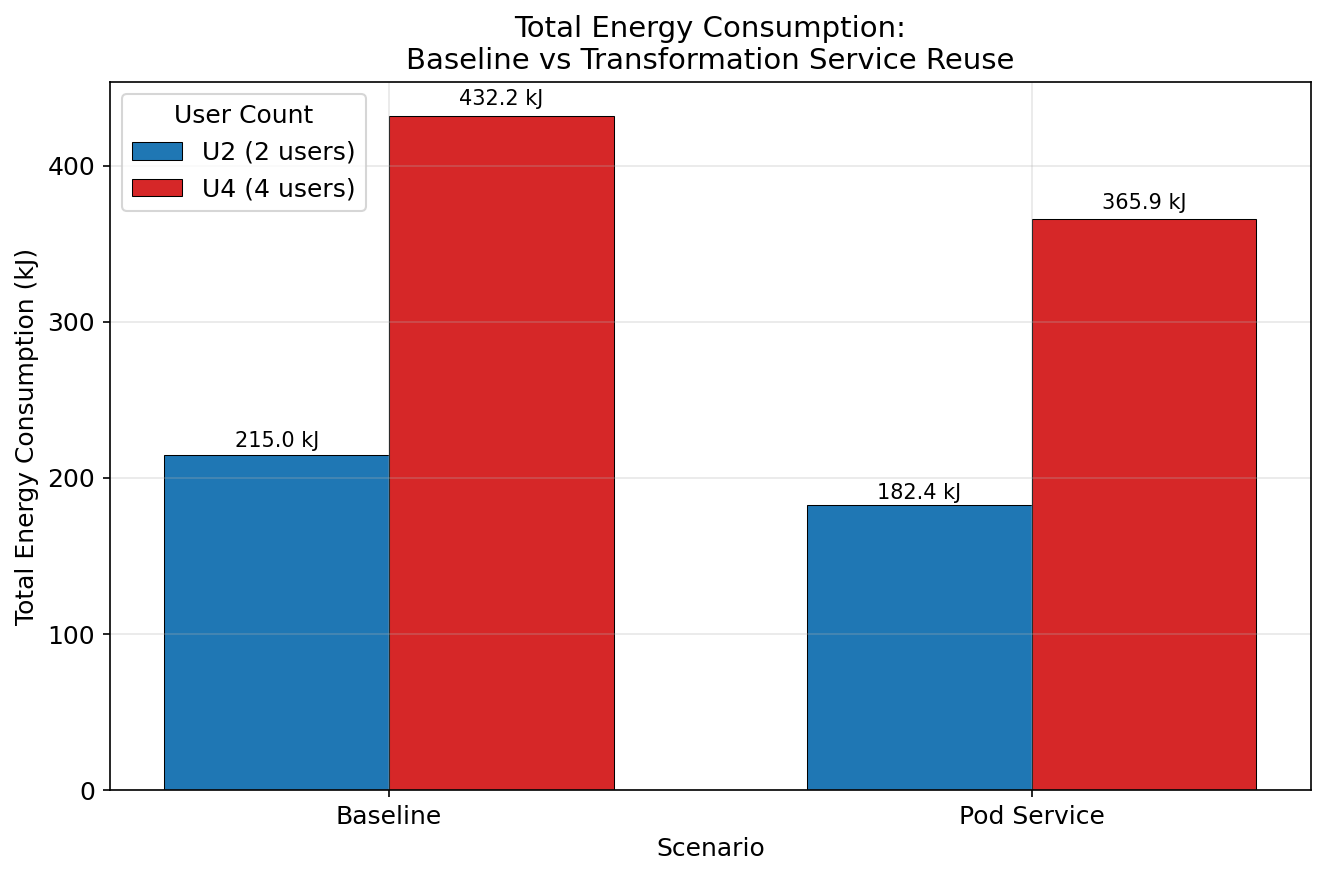

Saved: pod_service_energy.pdf  (U2 -15.2%, U4 -15.3%)


In [4]:
fig, ax = plt.subplots(figsize=(9, 6))

energy_u2 = [data[k]['energy_kj'] for k in keys_u2]
energy_u4 = [data[k]['energy_kj'] for k in keys_u4]

bars1 = ax.bar(x - width/2, energy_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, energy_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f} kJ', ha='center', va='bottom', fontsize=10)

# Annotate savings (computed)
e_save_u2 = pct_change('Baseline U2', 'Pod Service U2', 'energy_kj')
e_save_u4 = pct_change('Baseline U4', 'Pod Service U4', 'energy_kj')

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Energy Consumption (kJ)')
ax.set_title('Total Energy Consumption:\nBaseline vs Transformation Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/s2-pod_service_energy.pdf', bbox_inches='tight')
plt.savefig('plots/s2-pod_service_energy.png', bbox_inches='tight')
plt.show()
print(f'Saved: pod_service_energy.pdf  (U2 {e_save_u2:+.1f}%, U4 {e_save_u4:+.1f}%)')

## Plot 2 — Pipeline Duration

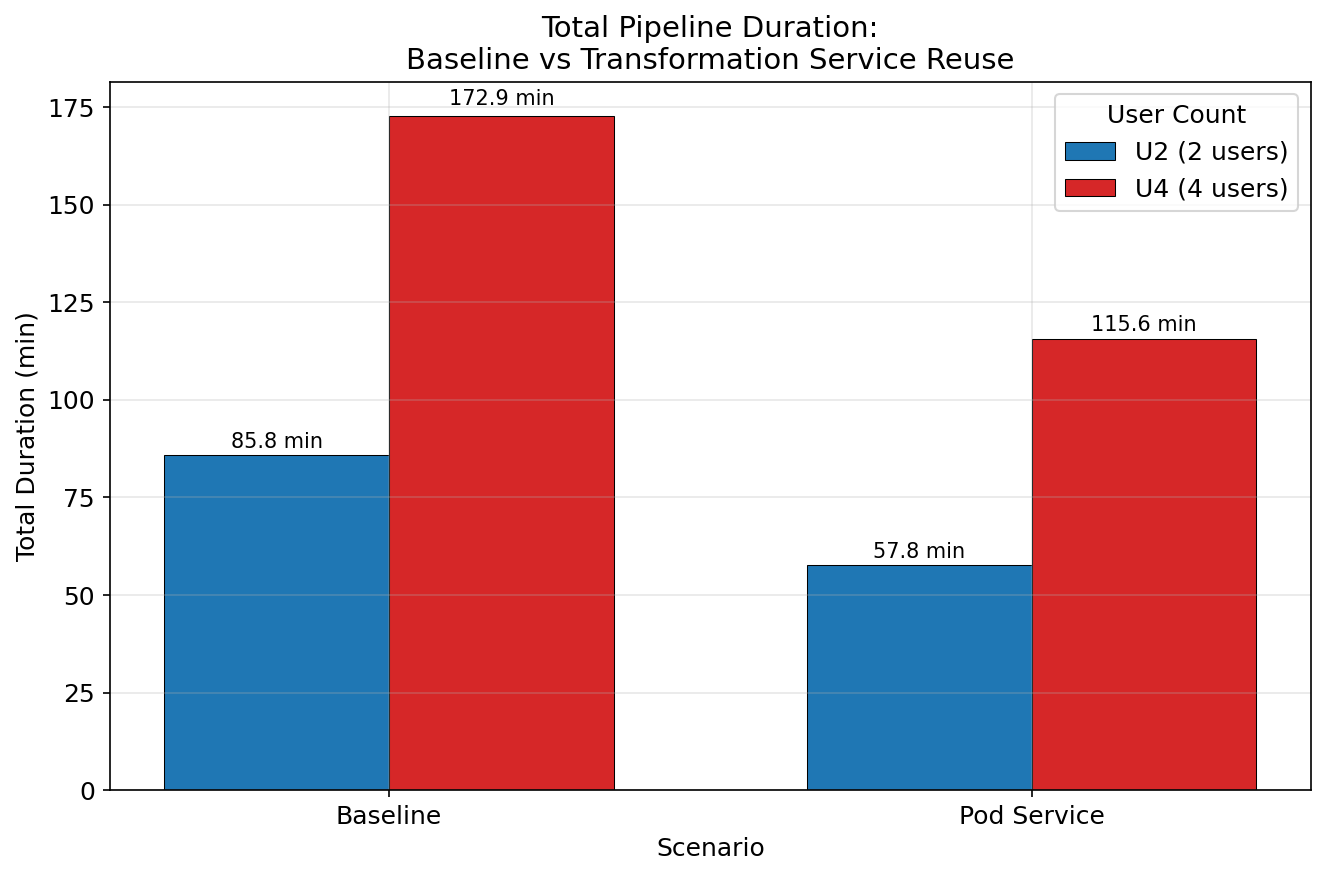

Saved: pod_service_duration.pdf  (U2 -32.6%, U4 -33.1%)


In [5]:
fig, ax = plt.subplots(figsize=(9, 6))

dur_u2 = [data[k]['duration_min'] for k in keys_u2]
dur_u4 = [data[k]['duration_min'] for k in keys_u4]

bars1 = ax.bar(x - width/2, dur_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, dur_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f} min', ha='center', va='bottom', fontsize=10)

d_save_u2 = pct_change('Baseline U2', 'Pod Service U2', 'duration_min')
d_save_u4 = pct_change('Baseline U4', 'Pod Service U4', 'duration_min')

ax.set_xlabel('Scenario')
ax.set_ylabel('Total Duration (min)')
ax.set_title('Total Pipeline Duration:\nBaseline vs Transformation Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/s2-pod_service_duration.pdf', bbox_inches='tight')
plt.savefig('plots/s2-pod_service_duration.png', bbox_inches='tight')
plt.show()
print(f'Saved: pod_service_duration.pdf  (U2 {d_save_u2:+.1f}%, U4 {d_save_u4:+.1f}%)')

## Plot 3 — System Throughput

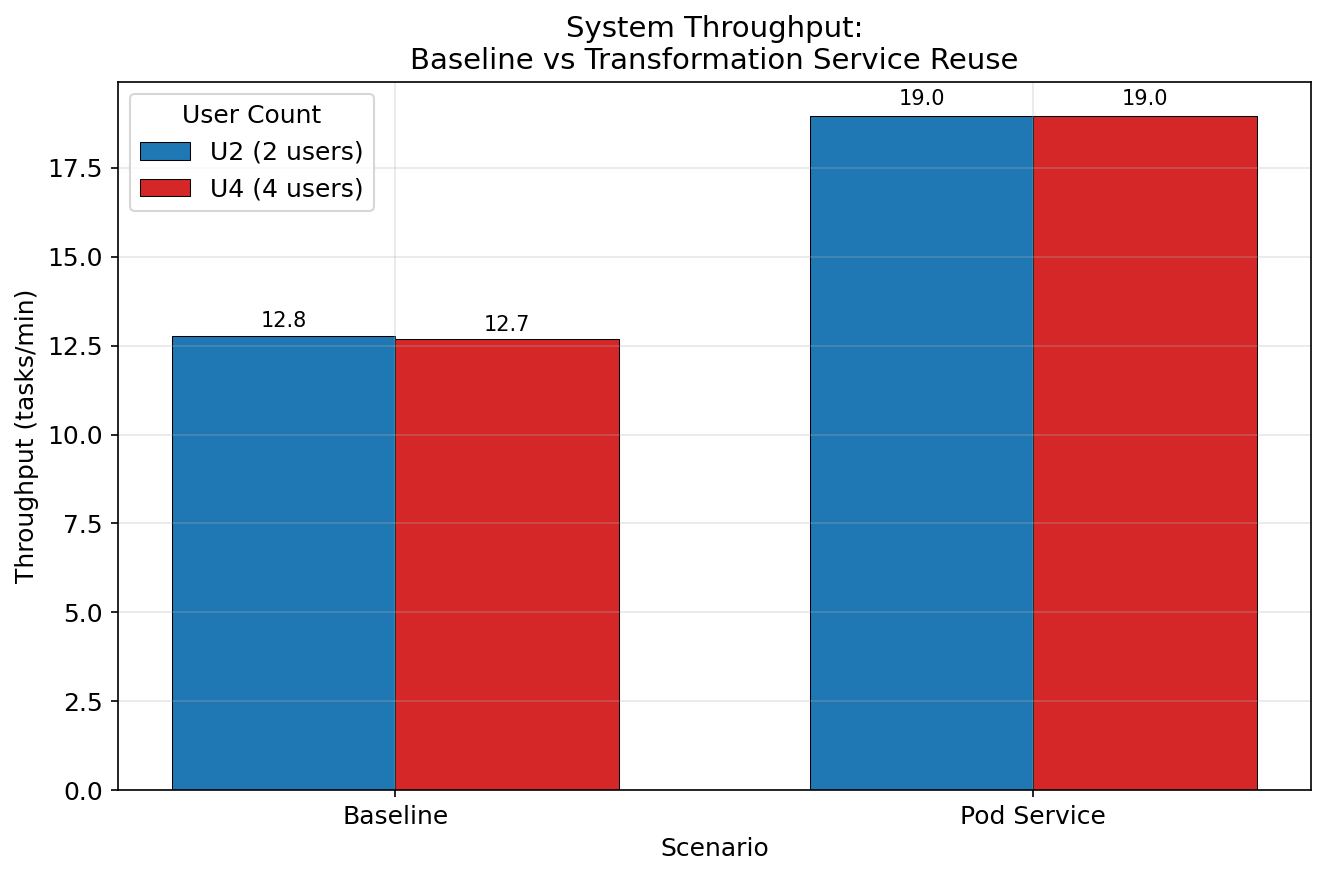

Saved: pod_service_throughput.pdf  (U2 +48.5%, U4 +49.6%)


In [6]:
fig, ax = plt.subplots(figsize=(9, 6))

tp_u2 = [data[k]['throughput'] for k in keys_u2]
tp_u4 = [data[k]['throughput'] for k in keys_u4]

bars1 = ax.bar(x - width/2, tp_u2, width, label='U2 (2 users)', color=colors_u2, edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x + width/2, tp_u4, width, label='U4 (4 users)', color=colors_u4, edgecolor='black', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}', ha='center', va='bottom', fontsize=10)

tp_gain_u2 = pct_change('Baseline U2', 'Pod Service U2', 'throughput')
tp_gain_u4 = pct_change('Baseline U4', 'Pod Service U4', 'throughput')

ax.set_xlabel('Scenario')
ax.set_ylabel('Throughput (tasks/min)')
ax.set_title('System Throughput:\nBaseline vs Transformation Service Reuse')
ax.set_xticks(x)
ax.set_xticklabels(scenarios)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/s2-pod_service_throughput.pdf', bbox_inches='tight')
plt.savefig('plots/s2-pod_service_throughput.png', bbox_inches='tight')
plt.show()
print(f'Saved: pod_service_throughput.pdf  (U2 {tp_gain_u2:+.1f}%, U4 {tp_gain_u4:+.1f}%)')

## Plot 4 — Combined Savings Summary

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))

metrics = ['Energy\nSaving', 'Duration\nSaving', 'Throughput\nGain']

# Report magnitudes of improvement: energy/duration are reductions, throughput is a gain
savings_u2 = [
    -pct_change('Baseline U2', 'Pod Service U2', 'energy_kj'),
    -pct_change('Baseline U2', 'Pod Service U2', 'duration_min'),
     pct_change('Baseline U2', 'Pod Service U2', 'throughput'),
]
savings_u4 = [
    -pct_change('Baseline U4', 'Pod Service U4', 'energy_kj'),
    -pct_change('Baseline U4', 'Pod Service U4', 'duration_min'),
     pct_change('Baseline U4', 'Pod Service U4', 'throughput'),
]

x3 = np.arange(len(metrics))
bars1 = ax.bar(x3 - width/2, savings_u2, width, label='U2 (2 users)', color='#6baed6', edgecolor='black', linewidth=0.5)
bars2 = ax.bar(x3 + width/2, savings_u4, width, label='U4 (4 users)', color='#ef6548', edgecolor='black', linewidth=0.5)

for bar in list(bars1) + list(bars2):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., h * 1.01, f'{h:.1f}%', ha='center', va='bottom', fontsize=10)

ax.axhline(y=0, color='black', linewidth=0.8)
ax.set_xlabel('Metric')
ax.set_ylabel('Improvement vs Baseline (%)')
ax.set_title('Performance Improvements:\nTransformation Service Reuse vs Baseline')
ax.set_xticks(x3)
ax.set_xticklabels(metrics)
ax.legend(title='User Count')
plt.tight_layout()
plt.savefig('plots/s2-pod_service_savings_summary.pdf', bbox_inches='tight')
plt.savefig('plots/s2-pod_service_savings_summary.png', bbox_inches='tight')
plt.show()
print('Saved: pod_service_savings_summary.pdf')